**ДЗ 2. Шум**

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

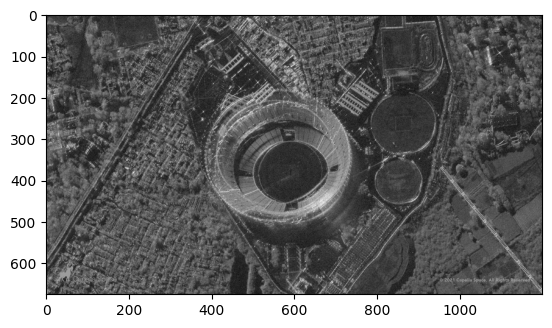

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap='gray')

**1. Зашумление изображений**

In [4]:
# Gaussian noise
mean = 0
stddev = 100

noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

array([[  0,  16,   0, ..., 111,   0,  80],
       [  1, 104,  68, ...,   0, 103,   0],
       [  0,   0,  51, ...,   0,   0, 145],
       ...,
       [  0,   0,  39, ..., 255,   0,  15],
       [  0,  34,   0, ...,   0,   5, 135],
       [160, 204,   0, ...,  21,   0, 109]],
      shape=(675, 1200), dtype=uint8)

In [5]:
image_noise_gauss = cv2.add(image_gray, noise_gauss)

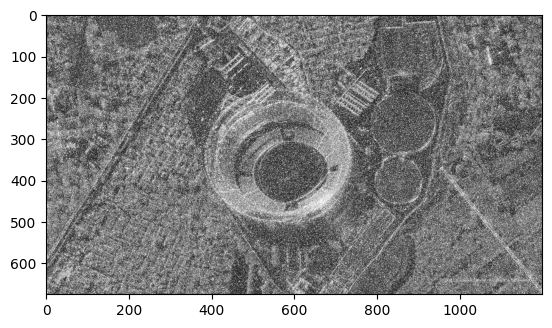

In [6]:
plt.imshow(image_noise_gauss, cmap='gray')

In [7]:
# постоянный шум
const_noise = np.full(image_gray.shape, 25, np.uint8)
image_const_noise = cv2.add(image_gray, const_noise)

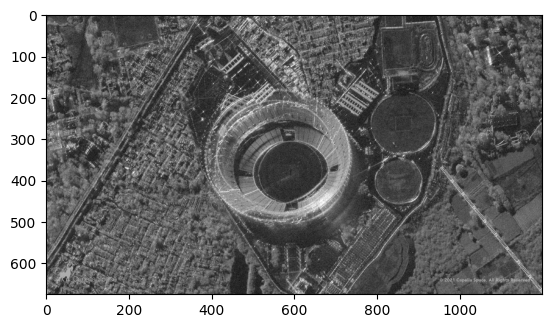

In [8]:
plt.imshow(image_const_noise, cmap='gray')

**2. Тестирование фильтров**

In [9]:
def print_metrics(name, original, result):
    mse =  mean_squared_error(original, result)
    ssim = structural_similarity(original, result)
    print(f'{name}     mse = {mse}   ssim = {ssim}')

In [10]:
print_metrics('Gauss noise', image_gray, image_noise_gauss)
print_metrics('Const noise', image_gray, image_const_noise)

Gauss noise     mse = 4230.673058024691   ssim = 0.18699266800035377
Const noise     mse = 624.9169679012346   ssim = 0.954407875487614


**3. Проверка фильтров с разными параметрами**

In [11]:
def test_filters(noisy_image):
    results = []

    # Медианный
    for k in [3, 5, 7]:
        filtered_image = cv2.medianBlur(noisy_image, k)
        results.append((f'Медианный, k={k}', filtered_image))

    # Гауссов
    for k in [3, 5, 7]:
        filtered_image = cv2.GaussianBlur(noisy_image, (k, k), 0)
        results.append((f'Гауссов, k={k}', filtered_image))

    # Билатеральный фильтр: d — диаметр области, sigma — сила сглаживания
    for d, sigma in [(5, 30), (9, 75), (15, 90)]:
        filtered_image = cv2.bilateralFilter(noisy_image, d, sigma, sigma)
        results.append((f'Билатеральный, d={d}, sigma={sigma}', filtered_image))

    # Фильтр нелокальных средних. Чем больше h, тем сильнее сглаживание
    for h in [5, 10, 15, 20]:
        filtered_image = cv2.fastNlMeansDenoising(noisy_image, h=h)
        results.append((f'Нелокальных средних, h={h}', filtered_image))

    return results

In [12]:
gauss_results = test_filters(image_noise_gauss)
const_results = test_filters(image_const_noise)

print('Фильтрация гауссова шума:')
for filterr, filtered_image in gauss_results:
    print_metrics(filterr, image_gray, filtered_image)

print('\nФильтрация постоянного шума:')
for filterr, filtered_image in const_results:
    print_metrics(filterr, image_gray, filtered_image)

Фильтрация гауссова шума:
Медианный, k=3     mse = 1038.0453432098766   ssim = 0.42824305715634176
Медианный, k=5     mse = 706.0308555555556   ssim = 0.47015171101208536
Медианный, k=7     mse = 682.5692432098765   ssim = 0.4335541754151257
Гауссов, k=3     mse = 1903.4527271604939   ssim = 0.4403070769112739
Гауссов, k=5     mse = 1764.6416320987655   ssim = 0.48595844595449306
Гауссов, k=7     mse = 1721.1959543209878   ssim = 0.49254914446712594
Билатеральный, d=5, sigma=30     mse = 3705.77162962963   ssim = 0.19010764884676115
Билатеральный, d=9, sigma=75     mse = 1837.5481913580247   ssim = 0.3144654024373729
Билатеральный, d=15, sigma=90     mse = 1639.3202209876542   ssim = 0.3188534920966512
Нелокальных средних, h=5     mse = 4230.673058024691   ssim = 0.18699266800035377
Нелокальных средних, h=10     mse = 4230.6725160493825   ssim = 0.1869927865141788
Нелокальных средних, h=15     mse = 4230.446954320988   ssim = 0.18706523005764128
Нелокальных средних, h=20     mse = 4226

In [15]:
def find_best_filter(original, results):
    best_filter = ''
    best_image = None
    best_mse = 0
    best_ssim = -1

    for filterr, filtered_image in results:
        mse = mean_squared_error(original, filtered_image)
        ssim = structural_similarity(original, filtered_image)
        if ssim > best_ssim:
            best_filter = filterr
            best_image = filtered_image
            best_mse = mse
            best_ssim = ssim

    return best_filter, best_image, best_mse, best_ssim

In [16]:
best_gauss = find_best_filter(image_gray, gauss_results)
best_const = find_best_filter(image_gray, const_results)

print('Best for gauss noise:')
print(best_gauss[0])
print(f'MSE = {best_gauss[2]:.2f}, SSIM = {best_gauss[3]:.4f}')

print('\nBest for const noise:')
print(best_const[0])
print(f'MSE = {best_const[2]:.2f}, SSIM = {best_const[3]:.4f}')

Best for gauss noise:
Гауссов, k=7
MSE = 1721.20, SSIM = 0.4925

Best for const noise:
Нелокальных средних, h=5
MSE = 629.46, SSIM = 0.9229


**Вывод**

Были протестированы четыре фильтра с разными параметрами. Для гауссова шума лучший результат показал гауссов фильтр, а для постоянного шума — фильтр Нелокальных средних.